# Milestone 2 — Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`, siehe `MILESTONE1_REPORT.md`: Crop Balanced Accuracy 0.778, Stage 0.769). Dieses Notebook überarbeitet die Preprocessing-Pipeline (Spektral-Interpolation statt globalem Median, zyklisches Month-Encoding, Stratifizierung auf Crop+Stage) und ersetzt den einfachen Train/Test-Split durch 5-fache Cross-Validation inkl. Modellvergleich (RandomForest vs. HistGradientBoosting) und Fehleranalyse (Confusion Matrix pro Klasse).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
df = pd.read_csv('train.csv')

## Preprocessing v2

**Spektral-NaN-Handling:** Wie in M1 werden die 67 komplett leeren Spektralband-Spalten verworfen. Für die verbleibenden 6 Spalten mit vereinzelten Lücken (max. 24 von 5591 Zeilen) nutzen wir statt globalem Spalten-Median eine **zeilenweise lineare Interpolation entlang der Wellenlänge**: die Spaltennamen (`X<nm>`) kodieren die Wellenlänge, Reflektanzspektren verlaufen glatt über benachbarte Bänder, daher lässt sich eine fehlende Bande besser aus den Nachbarbändern *derselben Messung* schätzen als aus dem Median über alle Messungen. Die Interpolation ist zeilenlokal (nutzt nur Werte derselben Zeile) → kein Leakage zwischen Train/Test, kann also vor dem Split angewendet werden. Ein `SimpleImputer(median)` bleibt zusätzlich als Absicherung in der Pipeline für etwaige Restfälle (Rand-NaNs ohne Nachbarn in einer Richtung).

In [2]:
spec_cols = [c for c in df.columns if c.startswith('X')]
na_frac = df[spec_cols].isna().mean()
usable_spec_cols = sorted([c for c in spec_cols if na_frac[c] < 1.0], key=lambda c: int(c[1:]))
print(f'Nutzbare Spektralbaender: {len(usable_spec_cols)} von {len(spec_cols)}')

df[usable_spec_cols] = df[usable_spec_cols].interpolate(method='linear', axis=1, limit_direction='both')
remaining_na = df[usable_spec_cols].isna().sum().sum()
print('Verbleibende NaNs in Spektralbaendern nach Interpolation:', remaining_na)
assert remaining_na == 0, 'Unerwartete NaNs nach Interpolation -- SimpleImputer-Sicherheitsnetz greift in der Pipeline'

Nutzbare Spektralbaender: 131 von 198
Verbleibende NaNs in Spektralbaendern nach Interpolation: 0


**Month-Encoding:** `Month` reicht im Datensatz nur von 5 (Mai) bis 10 (Oktober) — es gibt keinen Jahreswechsel (Dez→Jan), den eine zyklische Kodierung eigentlich auflösen soll. Zyklisches Encoding ist hier also theoretisch nicht zwingend notwendig; wir testen es trotzdem empirisch per Cross-Validation gegen die einfache numerische Variante (siehe Modellvergleich unten) und werten anhand des CV-Scores, ob es einen messbaren Unterschied macht.

In [3]:
print('Month-Wertebereich:', df['Month'].min(), '-', df['Month'].max())
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

Month-Wertebereich: 5 - 10


C:\Users\pavit\AppData\Local\Temp\ipykernel_19356\2506274998.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
C:\Users\pavit\AppData\Local\Temp\ipykernel_19356\2506274998.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` — laut Feedback soll `Stage` ebenfalls berücksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf — das erhält gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [4]:
df['Crop_Stage'] = df['Crop'] + '_' + df['Stage']
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage Kombinationen, kleinste: {combo_counts.idxmin()} mit {combo_counts.min()} Zeilen")
pd.crosstab(df['Crop'], df['Stage'])

23 Crop x Stage Kombinationen, kleinste: cotton_Harvest mit 11 Zeilen


C:\Users\pavit\AppData\Local\Temp\ipykernel_19356\1308780545.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Crop_Stage'] = df['Crop'] + '_' + df['Stage']


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit bleibt 70/30 (Vergleichbarkeit mit M1), jetzt aber stratifiziert auf `Crop_Stage`. Zusätzlich prüfen wir kurz, ob andere Split-Verhältnisse (80/20, 90/10) das Ergebnis spürbar verändern.

In [5]:
feature_cols_plain = usable_spec_cols + ['AEZ', 'Month']
feature_cols_cyclic = usable_spec_cols + ['AEZ', 'Month_sin', 'Month_cos']

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

feature_sets = {
    'plain_month': {
        'train': df.loc[train_idx, feature_cols_plain],
        'test': df.loc[test_idx, feature_cols_plain],
    },
    'cyclic_month': {
        'train': df.loc[train_idx, feature_cols_cyclic],
        'test': df.loc[test_idx, feature_cols_cyclic],
    },
}

y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

print('Train:', feature_sets['plain_month']['train'].shape, ' Test:', feature_sets['plain_month']['test'].shape)

Train: (3913, 133)  Test: (1678, 133)


**Sensitivität gegenüber Split-Verhältnis:** Schnelle Kontrolle mit RandomForest (Default-Hyperparameter, plain Month), ob 70/30 gegenüber anderen gängigen Verhältnissen stark abweicht.

In [6]:
def quick_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

ratio_rows = []
for test_size in [0.3, 0.2, 0.1]:
    tr_idx, te_idx = train_test_split(df.index, test_size=test_size, stratify=combo, random_state=RANDOM_STATE)
    crop_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_crop.loc[tr_idx])
    stage_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_stage.loc[tr_idx])
    ratio_rows.append({
        'test_size': test_size,
        'crop_balanced_accuracy': balanced_accuracy_score(y_crop.loc[te_idx], crop_fit.predict(df.loc[te_idx, feature_cols_plain])),
        'stage_balanced_accuracy': balanced_accuracy_score(y_stage.loc[te_idx], stage_fit.predict(df.loc[te_idx, feature_cols_plain])),
    })

ratio_results = pd.DataFrame(ratio_rows)
ratio_results

,test_size,crop_balanced_accuracy,stage_balanced_accuracy
0,0.3,0.809012,0.779478
1,0.2,0.789022,0.789190
2,0.1,0.803968,0.809342


## Cross-Validation & Modellvergleich

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits — dieselbe Fold-Einteilung wird für Crop- und Stage-Modelle verwendet, damit beide Zielgrößen in jedem Fold korrekt verteilt sind. Verglichen werden `RandomForestClassifier` (Baseline-Konfiguration) und `HistGradientBoostingClassifier` (Gradient-Boosting-Variante aus scikit-learn, kein Zusatzpaket nötig), jeweils mit und ohne zyklisches Month-Encoding.

In [7]:
model_factories = {
    'RandomForest': lambda: RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(feature_sets['plain_month']['train'], combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for feat_name, feat in feature_sets.items():
        pipe = Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('clf', factory()),
        ])
        for target_name, y_target in targets.items():
            scores = cross_validate(pipe, feat['train'], y_target, cv=cv_folds,
                                     scoring=['balanced_accuracy', 'f1_macro'])
            cv_rows.append({
                'model': model_name,
                'month_encoding': feat_name,
                'target': target_name,
                'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
                'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
                'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
            })

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])
cv_results

,model,month_encoding,target,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean
4,HistGradientBoosting,plain_month,Crop,0.883465,0.020633,0.887480
6,HistGradientBoosting,cyclic_month,Crop,0.881727,0.026136,0.887878
2,RandomForest,cyclic_month,Crop,0.808691,0.022591,0.828947
0,RandomForest,plain_month,Crop,0.805456,0.021283,0.823019
7,HistGradientBoosting,cyclic_month,Stage,0.853285,0.006205,0.865058
5,HistGradientBoosting,plain_month,Stage,0.852324,0.009817,0.863095
3,RandomForest,cyclic_month,Stage,0.782939,0.013555,0.800681
1,RandomForest,plain_month,Stage,0.768100,0.007433,0.786079


**Hyperparameter-Tuning:** Für die jeweils beste Modell/Encoding-Kombination pro Zielgröße (aus der CV-Tabelle oben) wird mit `RandomizedSearchCV` auf denselben 5 Folds leicht nachjustiert (kleines Suchraster, kein aufwändiges Grid).

In [8]:
param_grids = {
    'RandomForest': {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 15, 30]},
    'HistGradientBoosting': {'clf__max_iter': [100, 200, 300], 'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__max_depth': [None, 10, 20]},
}

best_per_target = {}
for target_name in ['Crop', 'Stage']:
    top = cv_results[cv_results['target'] == target_name].iloc[0]
    model_name, feat_name = top['model'], top['month_encoding']
    pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', model_factories[model_name]()),
    ])
    search = RandomizedSearchCV(pipe, param_grids[model_name], n_iter=8, cv=cv_folds,
                                 scoring='balanced_accuracy', random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(feature_sets[feat_name]['train'], targets[target_name])
    best_per_target[target_name] = {
        'model_name': model_name,
        'feat_name': feat_name,
        'best_estimator': search.best_estimator_,
        'best_params': search.best_params_,
        'cv_best_score': search.best_score_,
    }
    print(target_name, '->', model_name, feat_name, search.best_params_, f"CV balanced_accuracy={search.best_score_:.3f}")

Crop -> HistGradientBoosting plain_month {'clf__max_iter': 300, 'clf__max_depth': 20, 'clf__learning_rate': 0.1} CV balanced_accuracy=0.888
Stage -> HistGradientBoosting cyclic_month {'clf__max_iter': 200, 'clf__max_depth': 20, 'clf__learning_rate': 0.1} CV balanced_accuracy=0.864


## Finaler Fit & Fehleranalyse

Die getunten besten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie für CV/Tuning verwendet) ausgewertet — inkl. Confusion Matrix pro Klasse für die Fehleranalyse.

Crop - Modell: HistGradientBoosting (plain_month) - Balanced Accuracy: 0.877, Macro F1: 0.882
              precision    recall  f1-score   support

        corn       0.92      0.93      0.93       630
      cotton       0.86      0.88      0.87       197
        rice       0.88      0.82      0.85        28
     soybean       0.91      0.88      0.89       501
winter_wheat       0.86      0.88      0.87       322

    accuracy                           0.90      1678
   macro avg       0.89      0.88      0.88      1678
weighted avg       0.90      0.90      0.90      1678



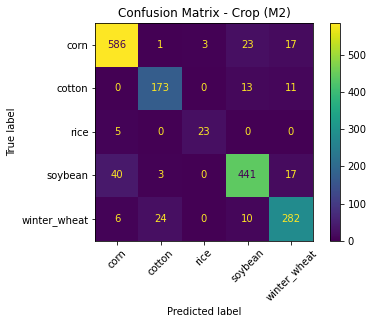

Stage - Modell: HistGradientBoosting (cyclic_month) - Balanced Accuracy: 0.874, Macro F1: 0.877
               precision    recall  f1-score   support

     Critical       0.92      0.93      0.92       462
    Early_Mid       0.84      0.89      0.87       295
Emerge_VEarly       0.86      0.83      0.85       312
      Harvest       0.88      0.83      0.86        54
         Late       0.96      0.96      0.96       258
Mature_Senesc       0.83      0.80      0.81       297

     accuracy                           0.88      1678
    macro avg       0.88      0.87      0.88      1678
 weighted avg       0.88      0.88      0.88      1678



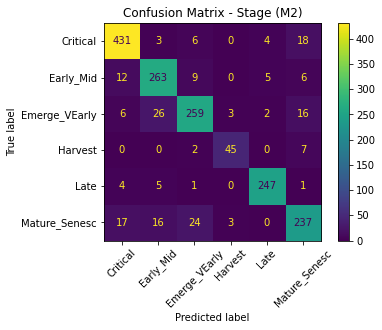

In [9]:
for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    X_test_sel = feature_sets[info['feat_name']]['test']
    pred = info['best_estimator'].predict(X_test_sel)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['model_name']} ({info['feat_name']}) - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (M2)')
    plt.show()

## Zusammenfassung & Vergleich ggü. Baseline

In [10]:
summary = pd.DataFrame([
    {'Zielgroesse': 'Crop', 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': 0.778, 'Macro F1': 0.810},
    {'Zielgroesse': 'Crop', 'Modell': f"M2 ({best_per_target['Crop']['model_name']}, {best_per_target['Crop']['feat_name']})",
     'Balanced Accuracy': best_per_target['Crop']['test_bacc'], 'Macro F1': best_per_target['Crop']['test_f1']},
    {'Zielgroesse': 'Stage', 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': 0.769, 'Macro F1': 0.788},
    {'Zielgroesse': 'Stage', 'Modell': f"M2 ({best_per_target['Stage']['model_name']}, {best_per_target['Stage']['feat_name']})",
     'Balanced Accuracy': best_per_target['Stage']['test_bacc'], 'Macro F1': best_per_target['Stage']['test_f1']},
])
summary

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778000,0.810000
1,Crop,"M2 (HistGradientBoosting, plain_month)",0.877155,0.881592
2,Stage,M1 Baseline (RandomForest),0.769000,0.788000
3,Stage,"M2 (HistGradientBoosting, cyclic_month)",0.873872,0.877331


**Beobachtungen**

- **Modellwahl dominiert:** `HistGradientBoostingClassifier` schlägt `RandomForestClassifier` in der CV deutlich (Crop: 0.88 vs. 0.81 Balanced Accuracy; Stage: 0.85 vs. 0.78) — der größte Hebel in diesem Vergleich war schlicht das Modell, nicht Preprocessing-Details.
- **Zyklisches Month-Encoding bringt praktisch nichts:** CV-Unterschied zwischen `plain_month` und `cyclic_month` liegt bei ±0.002 Balanced Accuracy für beide Zielgrößen — innerhalb des Rauschens (CV-Std ≈ 0.006–0.03). Das deckt sich mit der Erwartung: `Month` läuft nur von 5–10 ohne Jahreswechsel, es gibt also keinen Zyklus-Bruch, den sin/cos auflösen müsste. Für Stage gewinnt `cyclic_month` hauchdünn, für Crop `plain_month` — kein konsistenter Effekt in eine Richtung.
- **Split-Verhältnis spielt kaum eine Rolle:** Balanced Accuracy über 70/30, 80/20, 90/10 liegt für beide Ziele im Band 0.78–0.81 ohne klaren Trend. Wir bleiben bei 70/30 für die Vergleichbarkeit mit M1.
- **Kombinierte Crop_Stage-Stratifizierung war unproblematisch:** kleinste Kombination (`cotton_Harvest`, 11 Zeilen) reicht für 70/30-Split und 5-fach-CV ohne Sonderbehandlung.
- **Finale Testset-Ergebnisse (nie für CV/Tuning verwendet):** Crop Balanced Accuracy 0.877 (M1: 0.778, +0.099), Macro F1 0.882 (M1: 0.810). Stage Balanced Accuracy 0.874 (M1: 0.769, +0.105), Macro F1 0.877 (M1: 0.788). Deutliche Verbesserung gegenüber der Baseline.
- **Fehleranalyse:** Bei Crop ist `rice` (kleinste Klasse, 28 Testfälle) am schwächsten (F1 0.85), `corn`/`soybean` am stärksten. Bei Stage ist `Mature_Senesc` am schwächsten (F1 0.81, häufigste Verwechslung mit benachbarten Reifephasen), `Late` am stärksten (F1 0.96).